# Fraud scores

## What makes them different?

**What a score delivers, and why the promise changes when you move from credit risk to fraud.**

A credit score is a statement about _odds_. A fraud score is a promise to _legitimate customers_.
That difference is not cosmetic. It changes the calibration target, the quantity you can estimate
reliably, and how much data you need before a threshold means anything.

This notebook works through the argument on public data:

|                   | Credit risk                 | Fraud                                           |
| ----------------- | --------------------------- | ----------------------------------------------- |
| What you fear     | approving a defaulter       | blocking a good customer                        |
| Base rate         | percent-scale, moves slowly | basis-point scale, moves fast and adversarially |
| Natural invariant | log odds of good to bad     | false positive rate on legitimate traffic       |
| Score contract    | _points to double the odds_ | _this cut costs you x% of good customers_       |

Datasets, both pulled from OpenML so every number here is reproducible:
[Give Me Some Credit](https://www.openml.org/search?type=data&q=GiveMeSomeCredit)
(150,000 borrowers, 6.7% go 90 days delinquent) and
[Credit Card Fraud Detection](https://www.openml.org/d/1597) (284,807 transactions, 0.172% fraud).

_Written up from work in Chapter 6 of my forthcoming book on AWS AI/ML solutions. Everything below
is run end to end; the numbers in the prose come from the cells._


## Setup


In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier
from scipy.optimize import minimize_scalar
from sklearn.datasets import fetch_openml
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
%config InlineBackend.print_figure_kwargs = {'bbox_inches': None}

# Diagram style: Avenir, generous type, no chartjunk.
CREDIT = "#16B0F1"  # credit-risk blue
FRAUD = "#FF3D77"  # fraud pink
ACCENT = "#ED9A2E"  # amber, for anchors and annotation
INK = "#22252A"
GREY = "#9AA0A8"

plt.rcParams.update(
    {
        "font.family": "Avenir",
        "font.size": 12,
        "axes.titlesize": 14,
        "axes.titleweight": "medium",
        "axes.labelsize": 13,
        "axes.edgecolor": INK,
        "axes.labelcolor": INK,
        "text.color": INK,
        "xtick.color": INK,
        "ytick.color": INK,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.dpi": 250,
        "savefig.dpi": 500,
        "savefig.bbox": "tight",
        "legend.frameon": False,
        "axes.grid": False,
    }
)
FIGDIR = "figures"
RNG = np.random.default_rng(6)

## 1. The credit score: a statement about odds

A scorecard is not a probability. It is an affine function of the log odds:

$$
\text{score} = \text{offset} + \text{factor} \times \ln(\text{odds}), \qquad
\text{factor} = \frac{\text{PDO}}{\ln 2}
$$

PDO is _points to double the odds_. Fix two things and the scale is determined: an anchor
(say, 600 points means 50:1 good-to-bad) and a PDO (say, 20). Every 20 points thereafter doubles
the odds of a good account. That is the entire contract, and it is a contract about **odds**,
which is to say about the ratio of the two classes.


In [2]:
PDO, ANCHOR_SCORE, ANCHOR_ODDS = 20, 600, 50
FACTOR = PDO / np.log(2)
OFFSET = ANCHOR_SCORE - FACTOR * np.log(ANCHOR_ODDS)


def odds_to_score(odds):
    """Classic scorecard scaling: score = offset + factor * ln(odds of good to bad)."""
    return OFFSET + FACTOR * np.log(odds)


print(f"factor = {FACTOR:.2f} points per e-fold, offset = {OFFSET:.2f}")
for o in (10, 20, 50, 100, 200):
    print(f"odds {o:4d}:1 -> {odds_to_score(o):6.1f} points")

factor = 28.85 points per e-fold, offset = 487.12
odds   10:1 ->  553.6 points
odds   20:1 ->  573.6 points
odds   50:1 ->  600.0 points
odds  100:1 ->  620.0 points
odds  200:1 ->  640.0 points


In [3]:
credit = fetch_openml(name="GiveMeSomeCredit", as_frame=True, parser="auto").frame
y_credit = (
    (credit.pop("FinancialDistressNextTwoYears").astype(str) == "Yes")
    .astype(int)
    .values
)
X_credit = credit.astype(float)

Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(
    X_credit, y_credit, test_size=0.4, stratify=y_credit, random_state=6
)
print(
    f"Give Me Some Credit: {len(y_credit):,} borrowers, bad rate {y_credit.mean():.2%}"
)
print(f"holdout: {len(yc_te):,} rows, {yc_te.sum():,} bad")

Give Me Some Credit: 150,000 borrowers, bad rate 6.68%
holdout: 60,000 rows, 4,010 bad


Credit risk does not feed raw features to a logistic regression. It bins them and encodes each bin
by its weight of evidence, $\ln \frac{\text{share of goods}}{\text{share of bads}}$, so the model is
additive in log odds by construction. That is what makes the score linear in log odds at the end.


In [4]:
def fit_woe(X, y, n_bins=8):
    """Weight of evidence per feature: ln(share of goods / share of bads) within each quantile bin."""
    n_good, n_bad = (y == 0).sum(), (y == 1).sum()
    maps = {}
    for c in X.columns:
        median = X[c].median()
        edges = np.unique(np.nanquantile(X[c], np.linspace(0, 1, n_bins + 1))[1:-1])
        b = np.digitize(X[c].fillna(median), edges)
        table = {}
        for k in np.unique(b):
            good = max(((b == k) & (y == 0)).sum(), 0.5)  # 0.5 guards an empty cell
            bad = max(((b == k) & (y == 1)).sum(), 0.5)
            table[k] = np.log((good / n_good) / (bad / n_bad))
        maps[c] = (edges, table, median)
    return maps


def apply_woe(X, maps):
    """Encode each feature by the weight of evidence of the bin it falls into."""
    return pd.DataFrame(
        {
            c: [table.get(k, 0.0) for k in np.digitize(X[c].fillna(median), edges)]
            for c, (edges, table, median) in maps.items()
        },
        index=X.index,
    )


woe = fit_woe(Xc_tr, yc_tr)
credit_model = LogisticRegression(max_iter=3000).fit(apply_woe(Xc_tr, woe), yc_tr)
p_bad = credit_model.predict_proba(apply_woe(Xc_te, woe))[:, 1]
credit_score = odds_to_score((1 - p_bad) / p_bad)

print(f"holdout AUC {roc_auc_score(yc_te, p_bad):.3f}")
print(f"score range {credit_score.min():.0f} to {credit_score.max():.0f}")

holdout AUC 0.827
score range 480 to 636


Bin the holdout by score and read off the _empirical_ odds in each band. If the contract holds,
those observed odds fall on the contract line, and each 20 points of score doubles them. That is
the calibration test a scorecard has to pass.


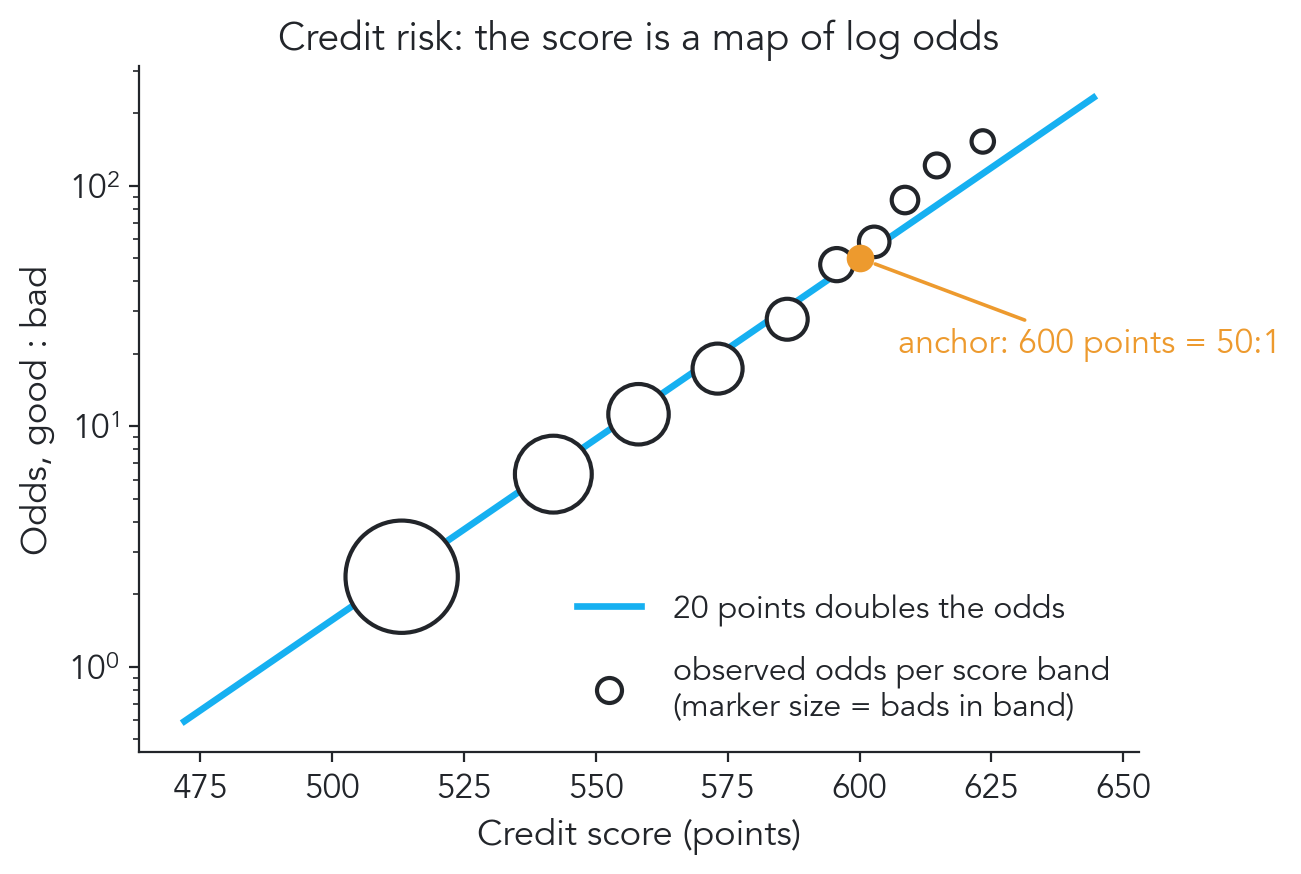

In [5]:
# -------------------------------------------------------------------------------
# Edges and bands for plotting the observed odds per score band
# -------------------------------------------------------------------------------
edges = np.quantile(credit_score, np.linspace(0, 1, 11))
band = np.clip(np.digitize(credit_score, edges[1:-1]), 0, len(edges) - 2)
rows = []
for b in range(len(edges) - 1):
    m = band == b
    n_bad, n_good = int(yc_te[m].sum()), int((1 - yc_te[m]).sum())
    if n_bad and n_good:
        rows.append((credit_score[m].mean(), n_good / n_bad, n_bad))
band_score, band_odds, band_bads = map(np.array, zip(*rows, strict=False))

# -------------------------------------------------------------------------------
# Plot
# -------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 4.9), dpi=200)
fig.subplots_adjust(left=0.10, right=0.6, top=0.80, bottom=0.1)
grid = np.linspace(credit_score.min() - 8, credit_score.max() + 8, 200)
ax.plot(grid, np.exp((grid - OFFSET) / FACTOR), color=CREDIT, lw=2.4)
ax.scatter(
    band_score,
    band_odds,
    s=band_bads * 0.9 + 30,
    color="white",
    edgecolor=INK,
    zorder=3,
    lw=1.5,
)
ax.scatter([ANCHOR_SCORE], [ANCHOR_ODDS], s=80, color=ACCENT, zorder=4)
ax.annotate(
    f"anchor: {ANCHOR_SCORE} points = {ANCHOR_ODDS}:1",
    xy=(ANCHOR_SCORE, ANCHOR_ODDS),
    xytext=(14, -34),
    textcoords="offset points",
    color=ACCENT,
    fontsize=12,
    ha="left",
    arrowprops=dict(arrowstyle="-", color=ACCENT, lw=1.3, shrinkA=2, shrinkB=6),
)
band_handle = plt.Line2D(
    [],
    [],
    marker="o",
    ls="",
    markersize=9,
    markerfacecolor="white",
    markeredgecolor=INK,
    markeredgewidth=1.5,
)
contract_handle = plt.Line2D([], [], color=CREDIT, lw=2.4)
ax.legend(
    [contract_handle, band_handle],
    [
        f"{PDO} points doubles the odds",
        "observed odds per score band\n(marker size = bads in band)",
    ],
    loc="lower right",
    fontsize=11.5,
    handletextpad=1.0,
    labelspacing=0.9,
)
ax.set_yscale("log")
ax.set_xlabel("Credit score (points)", fontweight="bold")
ax.set_ylabel("Odds, good : bad")
ax.set_title("Credit risk: the score is a map of log odds")
fig.savefig(f"{FIGDIR}/fig1_credit_log_odds.png", dpi=300)
plt.show()

The line is the promise; the circles are what the holdout delivered. It tracks from 2:1 up to about
60:1, then the top bands drift optimistic, and the shrinking markers say why: the best band contains
39 bad accounts. Even here, at the easy end of the imbalance spectrum, the odds contract runs out of
denominator eventually.

But it runs out _late_. Six point seven percent of this book goes bad, so nine of the ten bands have
enough of each class to estimate an odds ratio, and the base rate of a lending portfolio moves slowly
enough that the anchor stays put between refits. Both of those things are about to stop being true.

## 2. Fraud breaks the odds logic

Same instinct, applied to card fraud. The fraud rate in the public benchmark is 0.172%,
roughly **one in 580** transactions, and that is a _quiet_ week.


In [6]:
cc = fetch_openml(data_id=1597, as_frame=True, parser="auto").frame
y_fraud = cc.pop("Class").astype(int).values
X_fraud = cc.values

Xf_tr, Xf_te, yf_tr, yf_te = train_test_split(
    X_fraud, y_fraud, test_size=0.7, stratify=y_fraud, random_state=6
)
fraud_lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(
    Xf_tr, yf_tr
)
fraud_cat = CatBoostClassifier(
    iterations=500, depth=6, learning_rate=0.05, random_seed=6, verbose=0
).fit(Xf_tr, yf_tr)

p_lr = fraud_lr.predict_proba(Xf_te)[:, 1]
p_cat = fraud_cat.predict_proba(Xf_te)[:, 1]
n_legit = int((yf_te == 0).sum())

print(
    f"Credit Card Fraud: {len(y_fraud):,} transactions, fraud rate {y_fraud.mean():.3%}"
)
print(f"holdout: {n_legit:,} legitimate, {int(yf_te.sum())} fraud")
print(
    f"AUC logistic {roc_auc_score(yf_te, p_lr):.3f} CatBoost {roc_auc_score(yf_te, p_cat):.3f}"
)
print(
    f"\ngood-to-bad ratio, lending {(1 - y_credit.mean()) / y_credit.mean():.0f}:1"
    f"card fraud {(1 - y_fraud.mean()) / y_fraud.mean():.0f}:1"
)

Credit Card Fraud: 284,807 transactions, fraud rate 0.173%
holdout: 199,021 legitimate, 344 fraud
AUC logistic 0.963 CatBoost 0.978

good-to-bad ratio, lending 14:1card fraud 578:1


FPR is a conditional on the legitimate population only,
and the legitimate population is the stable one. That is the whole reason fraud teams contract on FPR.


In [7]:
class FPRScore:
    """Map a fraud probability to a 0-1000 score whose cuts carry a known false alarm rate."""

    def __init__(self, gamma: float = 5.0):
        self.gamma = gamma

    def fit(self, proba, y):
        """Freeze the legitimate score distribution. This ships with the model."""
        self.legit_ = np.sort(np.asarray(proba, float)[np.asarray(y) == 0])
        return self

    def transform(self, proba):
        """Percentile among legitimates, raised to gamma, on a 0-1000 dial."""
        r = np.searchsorted(self.legit_, np.asarray(proba, float), side="right") / len(
            self.legit_
        )
        return np.round(1000 * r**self.gamma).astype(int)

    def score_to_fpr(self, score):
        """The false alarm rate a cut carries. Exact and invertible."""
        return 1 - (np.asarray(score, float) / 1000) ** (1 / self.gamma)

## 3. FPR curves

Amazon Fraud Detector (now closed to new customers) shipped a 0-1000 score and published seven
anchor points relating score to estimated FPR. No functional form, just the table.
If the reasoning above is right, that table should sit close to a power of the legitimate
percentile. Fit $\gamma$ and see.


In [8]:
AFD = pd.DataFrame(
    {
        "score": [975, 950, 900, 860, 775, 700, 600],
        "fpr": [0.005, 0.01, 0.02, 0.03, 0.05, 0.07, 0.10],
    }
)
r_afd = 1 - AFD["fpr"].values
implied = np.log(AFD["score"].values / 1000) / np.log(r_afd)
gamma_ls = minimize_scalar(
    lambda g: np.sum((1000 * r_afd**g - AFD["score"].values) ** 2),
    bounds=(1, 12),
    method="bounded",
).x

GAMMA = 5.0
AFD["implied gamma"] = implied.round(3)
AFD["gamma = 5"] = (1000 * r_afd**GAMMA).round(1)
AFD["error"] = (AFD["gamma = 5"] - AFD["score"]).round(1)

print(AFD.to_string(index=False))
print(
    f"\nimplied gamma spans {implied.min():.2f} to {implied.max():.2f}, "
    f"mean {implied.mean():.2f}"
)
print(f"least-squares fit over all seven anchors: gamma = {gamma_ls:.3f}")
print(
    f"gamma = {GAMMA:.0f} reproduces the published table to "
    f"{np.abs(AFD['error']).mean():.1f} points mean absolute error on a 0-1000 scale "
    f"(worst {np.abs(AFD['error']).max():.0f})"
)

 score   fpr  implied gamma  gamma = 5  error
   975 0.005          5.051      975.2    0.2
   950 0.010          5.104      951.0    1.0
   900 0.020          5.215      903.9    3.9
   860 0.030          4.952      858.7   -1.3
   775 0.050          4.969      773.8   -1.2
   700 0.070          4.915      695.7   -4.3
   600 0.100          4.848      590.5   -9.5

implied gamma spans 4.85 to 5.22, mean 5.01
least-squares fit over all seven anchors: gamma = 4.912
gamma = 5 reproduces the published table to 3.1 points mean absolute error on a 0-1000 scale (worst 10)


Every anchor implies a $\gamma$ between 4.85 and 5.22, and a single round number, $\gamma = 5$,
lands within about 3 points out of 1000 across the whole table, four of the seven within two points:

$$\text{score} \approx 1000 \cdot (1 - \text{FPR})^{5}$$

Read that for what it is. Seven smooth monotone points are easy to fit with one free parameter, and
AFD's actual calibration is proprietary and no longer queryable, so this is not evidence about what
Amazon computed internally. What it does establish is the useful part: a published, operationally
sane FPR scale is well described by a power of the legitimate percentile, which means you can build
one yourself, pick $\gamma$ from a single anchor you care about, and get a dial that behaves the way
a fraud team expects.


cut  168  target 30.000%  observed 30.3012%  rel err   +1.0%
cut  423  target 15.824%  observed 16.0254%  rel err   +1.3%
cut  647  target  8.346%  observed  8.5790%  rel err   +2.8%
cut  798  target  4.402%  observed  4.6578%  rel err   +5.8%
cut  889  target  2.322%  observed  2.5545%  rel err  +10.0%
cut  940  target  1.225%  observed  1.3898%  rel err  +13.5%
cut  968  target  0.646%  observed  0.7587%  rel err  +17.4%
cut  983  target  0.341%  observed  0.4130%  rel err  +21.2%
cut  991  target  0.180%  observed  0.2362%  rel err  +31.4%
cut  995  target  0.095%  observed  0.1407%  rel err  +48.4%
cut  998  target  0.050%  observed  0.0523%  rel err   +4.5%


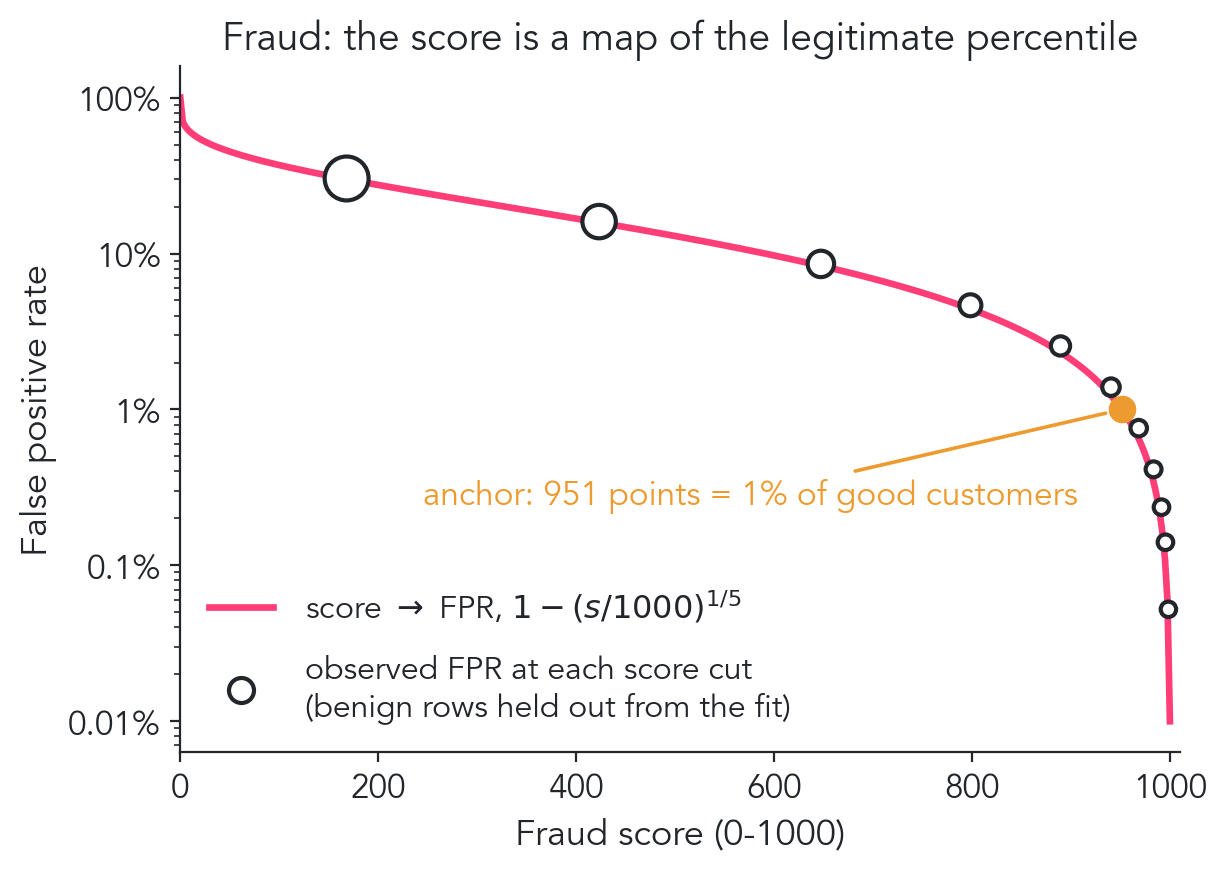

In [17]:
# -------------------------------------------------------------------------------
# The fraud dial, checked on benign rows the calibration never saw
# -------------------------------------------------------------------------------
# Fit the percentile grid on one slice of the holdout and measure FPR on the other.
# Fitting and measuring on the same benign rows makes the check true by construction.
cal_idx, ev_idx = train_test_split(
    np.arange(len(yf_te)), test_size=0.5, stratify=yf_te, random_state=11
)
y_ev = yf_te[ev_idx]

fpr_scorer = FPRScore(gamma=GAMMA).fit(p_lr[cal_idx], yf_te[cal_idx])
fraud_score = fpr_scorer.transform(p_lr[ev_idx])
legit_score = fraud_score[y_ev == 0]

# Cuts spread over FPR decades, not over percentiles: 1000 * r**5 rounds to 0 for
# every r below about 0.2, so percentile-spaced cuts pile up at the bottom of the dial.
targets_fpr = np.geomspace(0.30, 0.0005, 11)
band_cut = np.round(1000 * (1 - targets_fpr) ** GAMMA).astype(int)
band_fpr = np.array([(legit_score >= c).mean() for c in band_cut])
band_legit = np.array(
    [
        int(((legit_score >= c) & (legit_score < hi)).sum())
        for c, hi in zip(band_cut, np.r_[band_cut[1:], 1001], strict=False)
    ]
)
keep = band_fpr > 0
band_cut, band_fpr, band_legit = band_cut[keep], band_fpr[keep], band_legit[keep]

for c, t, f in zip(band_cut, targets_fpr[keep], band_fpr, strict=False):
    print(
        f"cut {c:>4}  target {t:>7.3%}  observed {f:>8.4%}  rel err {(f - t) / t:>+7.1%}"
    )

# -------------------------------------------------------------------------------
# Plot
# -------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 4.9), dpi=200)
fig.subplots_adjust(left=0.10, right=0.6, top=0.80, bottom=0.1)

grid = np.linspace(0, 999.5, 400)
ax.plot(grid, 1 - (grid / 1000) ** (1 / GAMMA), color=FRAUD, lw=2.4)
ax.scatter(
    band_cut,
    band_fpr,
    s=band_legit / band_legit.max() * 220 + 30,
    color="white",
    edgecolor=INK,
    zorder=3,
    lw=1.5,
)

ANCHOR_FPR = 0.01
ANCHOR_FRAUD_SCORE = 1000 * (1 - ANCHOR_FPR) ** GAMMA
ax.scatter([ANCHOR_FRAUD_SCORE], [ANCHOR_FPR], s=80, color=ACCENT, zorder=4)
ax.annotate(
    f"anchor: {ANCHOR_FRAUD_SCORE:.0f} points = {ANCHOR_FPR:.0%} of good customers",
    xy=(ANCHOR_FRAUD_SCORE, ANCHOR_FPR),
    xytext=(-16, -34),
    textcoords="offset points",
    color=ACCENT,
    fontsize=12,
    ha="right",
    arrowprops=dict(arrowstyle="-", color=ACCENT, lw=1.3, shrinkA=2, shrinkB=6),
)

band_handle = plt.Line2D(
    [],
    [],
    marker="o",
    ls="",
    markersize=9,
    markerfacecolor="white",
    markeredgecolor=INK,
    markeredgewidth=1.5,
)
contract_handle = plt.Line2D([], [], color=FRAUD, lw=2.4)
ax.legend(
    [contract_handle, band_handle],
    [
        rf"score $\rightarrow$ FPR, $1 - (s/1000)^{{1/{GAMMA:.0f}}}$",
        "observed FPR at each score cut\n(benign rows held out from the fit)",
    ],
    loc="lower left",
    fontsize=11.5,
    handletextpad=1.0,
    labelspacing=0.9,
)

ax.set_yscale("log")
ax.set_xlim(0, 1010)
ax.set_xlabel("Fraud score (0-1000)", fontweight="bold")
ax.set_ylabel("False positive rate")
ax.set_title("Fraud: the score is a map of the legitimate percentile")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}" if v >= 0.01 else f"{v * 100:g}%")
fig.savefig(f"{FIGDIR}/fig1b_fraud_percentile.png", dpi=300)
plt.show()

The practical payoff. Fraud models get retrained constantly, because the malicious distribution
drifts while the benign one holds still. Retraining moves the raw scores. It should not move
what a threshold _means_ to the business, or every downstream rule, queue and SLA breaks at once.

Take two genuinely different detectors on the same data, a logistic regression and a CatBoost
ensemble, and ask each for the cut that costs 1% of good customers.


In [10]:
def tail_fpr(legit_sorted, thresholds):
    """Share of legitimate transactions at or above each threshold."""
    n = len(legit_sorted)
    return (n - np.searchsorted(legit_sorted, thresholds, side="left")) / n


detectors = {"logistic regression": p_lr, "CatBoost": p_cat}
targets = [0.10, 0.05, 0.01, 0.001]
rows = []
for name, p in detectors.items():
    # Same calibrate-here, measure-there split as the figure above.
    legit_cal = np.sort(p[cal_idx][yf_te[cal_idx] == 0])
    score_ev = (
        FPRScore(gamma=GAMMA).fit(p[cal_idx], yf_te[cal_idx]).transform(p[ev_idx])
    )
    for t in targets:
        raw = np.quantile(legit_cal, 1 - t)
        cut = round(1000 * (1 - t) ** GAMMA)
        rows.append(
            {
                "model": name,
                "target FPR": f"{t:.1%}",
                "raw cut": f"{raw:.4g}",
                "score cut": cut,
                "FPR delivered": f"{(score_ev[y_ev == 0] >= cut).mean():.3%}",
                "TPR": f"{(score_ev[y_ev == 1] >= cut).mean():.1%}",
            }
        )
print(pd.DataFrame(rows).to_string(index=False))

              model target FPR   raw cut  score cut FPR delivered   TPR
logistic regression      10.0% 0.0008549        590       10.137% 89.5%
logistic regression       5.0%  0.001417        774        5.172% 86.6%
logistic regression       1.0%    0.0042        951        1.144% 83.1%
logistic regression       0.1%   0.01399        995        0.141% 76.7%
           CatBoost      10.0% 0.0001441        590       10.137% 93.0%
           CatBoost       5.0% 0.0002753        774        5.143% 87.2%
           CatBoost       1.0%  0.001225        951        1.114% 83.1%
           CatBoost       0.1%  0.008199        995        0.112% 80.2%


Read the `raw cut` column and then the `score cut` column. The raw cuts have nothing in common,
because they are properties of a particular fitted model. The score cuts are identical across both
detectors, because they are defined on the legitimate percentile rather than on whatever the model
happened to emit this quarter. Both land close to the promised rate on benign rows the calibration
never saw, and both drift wide in the deep tail, where there are simply too few good customers left
to pin the number down. What legitimately differs is TPR: at the same 1% cost to good customers,
CatBoost catches more fraud, and that is exactly the comparison you want a score scale to expose.


## Summary

- A credit score is calibrated to **odds**, because both classes are well populated and the base
  rate is stable. Points to double the odds is a contract you can keep.
- A fraud score should be calibrated to **FPR**, because prevalence is adversarial and the only
  large, stable, well-measured population you have is the legitimate one.
- Both scales are the same idea, a monotone map from a rate to a dial. Pick the dial to match your
  operating band: a power of the percentile for consumer fraud, log FPR for the deep tail.
- Amazon Fraud Detector's published table is fitted to within 3 points out of 1000 by
  $1000 \cdot (1-\text{FPR})^5$, which is a convenient shape to borrow, not a claim about AFD's internals.
- Calibration cannot manufacture resolution. Before promising a deep-tail FPR, check that the model
  still has distinct scores down there; a coarse output grid cannot deliver a fine cut, however you
  scale it.
- The promise is bounded below by $n \approx 4/(r^2 p)$ legitimate samples, and bounded above by
  how mature your fraud labels are, with the label-noise penalty scaling with prevalence.

**Sources**

- K. Berlin, _Full-range Binary Classifier Calibration for Stable Model Updates in Production_, [arXiv:2607.05481](https://arxiv.org/abs/2607.05481) (Cisco AI Defense); implementation at [cisco-ai-defense/fpr-model-calibration](https://github.com/cisco-ai-defense/fpr-model-calibration).
- J. Tittelfitz, _FPR Estimation for Fraud Detection in the Presence of Class-Conditional Label Noise_, [arXiv:2308.02695](https://arxiv.org/abs/2308.02695) (AWS Fraud Prevention).
- Amazon Fraud Detector model-score/FPR table, from the AWS documentation.
- Datasets: [OpenML 31](https://www.openml.org/d/31) (German Credit), [OpenML 1597](https://www.openml.org/d/1597) (Credit Card Fraud Detection, ULB).
